# Particle Swarm Optimization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def rosenbrock(p):
    x, y = p
    return (1 - x)**2 + 100 * (y - x**2)**2

In [3]:
n_particles = 30
lower = np.array([-2.0, -1.0])
upper = np.array([2.0, 3.0])
w = 0.7
c1 = 1.5
c2 = 1.5
max_iterations = 100

In [4]:
def pso(n_particles, w, c1, c2, max_iterations, seed=1):
    rng = np.random.default_rng(seed)
    pos = rng.uniform(lower, upper, (n_particles, 2))
    vel = rng.uniform(-0.2, 0.2, (n_particles, 2))
    pbest = pos.copy()
    pbest_val = np.array([rosenbrock(p) for p in pos])
    g = pbest_val.argmin()
    gbest, gbest_val = pbest[g].copy(), pbest_val[g]
    history = [gbest_val]
    for _ in range(max_iterations):
        r1, r2 = rng.random((2, n_particles, 2))
        vel = w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos)
        pos = np.clip(pos + vel, lower, upper)
        val = np.array([rosenbrock(p) for p in pos])
        better = val < pbest_val
        pbest[better], pbest_val[better] = pos[better], val[better]
        g = pbest_val.argmin()
        if pbest_val[g] < gbest_val:
            gbest, gbest_val = pbest[g].copy(), pbest_val[g]
        history.append(gbest_val)
    return gbest, gbest_val, history

In [5]:
gbest, gbest_val, history = pso(n_particles, w, c1, c2, max_iterations)

print("Best Position   :", gbest)
print("Minimum Value   :", gbest_val)
print("Theoretical Min : [1, 1], f = 0")

Best Position   : [0.99778479 0.99557816]
Minimum Value   : 4.908494217485674e-06
Theoretical Min : [1, 1], f = 0


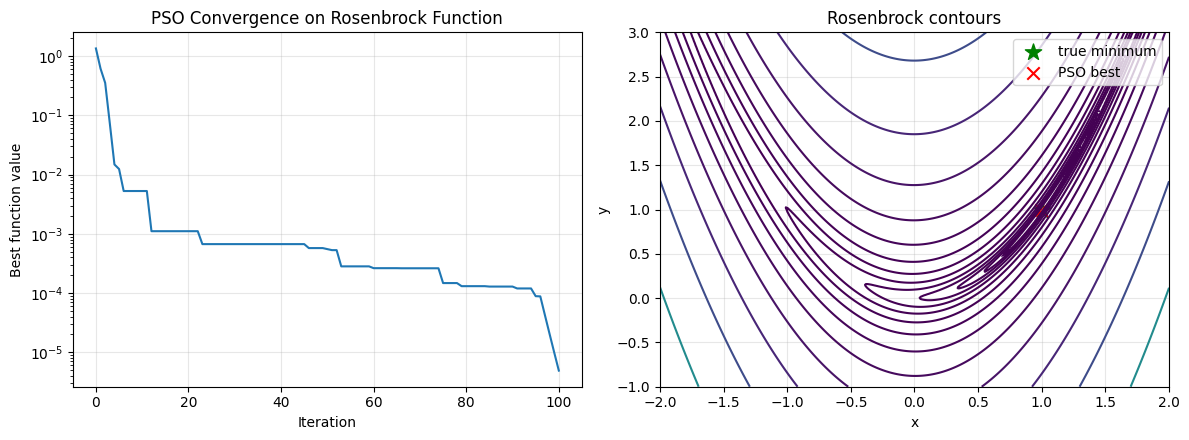

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].semilogy(history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Best function value")
ax[0].set_title("PSO Convergence on Rosenbrock Function")

gx, gy = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
ax[1].contour(gx, gy, (1 - gx)**2 + 100 * (gy - gx**2)**2, levels=np.logspace(-1, 3.5, 15), cmap="viridis")
ax[1].scatter(1, 1, c="green", marker="*", s=150, label="true minimum")
ax[1].scatter(*gbest, c="red", marker="x", s=80, label="PSO best")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title("Rosenbrock contours")
ax[1].legend()

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
settings = [
    ("Number of Particles", "30", "10", dict(n_particles=10)),
    ("Inertia Weight w", "0.70", "0.40", dict(w=0.4)),
    ("Cognitive c1", "1.50", "2.50", dict(c1=2.5)),
    ("Maximum Iterations", "100", "250", dict(max_iterations=250)),
]
base = dict(n_particles=n_particles, w=w, c1=c1, c2=c2, max_iterations=max_iterations)
rows = []
for name, old, new, change in settings:
    pos_, val_, _ = pso(**{**base, **change})
    rows.append([name, old, new, f"{gbest_val:.4e}", f"{val_:.4e}", np.array2string(pos_, precision=4)])
table = pd.DataFrame(rows, columns=["Parameter", "Original", "Modified", "Original f", "Modified f", "Modified Best Position"])
table

,Parameter,Original,Modified,Original f,Modified f,Modified Best Position
0,Number of Particles,30,10,4.9085e-06,1.9917e-05,[1.0043 1.0088]
1,Inertia Weight w,0.70,0.40,4.9085e-06,1.2869e-11,[1. 1.]
2,Cognitive c1,1.50,2.50,4.9085e-06,2.3303e-04,[0.9861 0.9718]
3,Maximum Iterations,100,250,4.9085e-06,3.4593e-11,[1. 1.]
